# Create dataset for card strength training

1. Get all available cards
2. Search for labels in json files
3. Create features
4. Export

_Consider calculating strength per type -> Edgar Markov scores really low_

In [1]:
import os
import pandas as pd
import numpy as np
import json
import ast
import matplotlib.pyplot as plt
import seaborn as sns
import re
from sentence_transformers import SentenceTransformer

from edhrec_card_scraper import sluggify_card_name
from src.dataset_filter import filter_dataset


C:\Users\ruflu\AppData\Roaming\Python\Python312\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
INPUT_DATA_PATH = "data/scryfall/oracle-cards-20251022090300.json"
OUTPUT_DATA_PATH = "card_strength_dataset.parquet"
EDHREC_CARD_DIRECTORY = "data/edhrec/cards"

In [3]:
df = pd.read_json(INPUT_DATA_PATH)
df = filter_dataset(df)

print(f"shape: {df.shape}")
df.head()

Loading dataset...
Cleaning text encodings...
Dataset has been filtered and cleaned.
shape: (29677, 15)


,oracle_id,name,card_faces,mana_cost,cmc,type_line,oracle_text,power,toughness,loyalty,colors,color_identity,keywords,game_changer,set
0,00037840-6089-42ec-8c5c-281f9f474504,"Nissa, Worldsoul Speaker",NaN,{3}{G},4.0,Legendary Creature — Elf Druid,"Landfall — Whenever a land you control enters,...",3,3,NaN,[G],[G],[Landfall],False,drc
1,0004ebd0-dfd6-4276-b4a6-de0003e94237,Static Orb,NaN,{3},3.0,Artifact,"As long as this artifact is untapped, players ...",NaN,NaN,NaN,[],[],[],False,7ed
2,0006faf6-7a61-426c-9034-579f2cfcfa83,Sensory Deprivation,NaN,{U},1.0,Enchantment — Aura,Enchant creature\nEnchanted creature gets -3/-0.,NaN,NaN,NaN,[U],[U],[Enchant],False,m14
3,0007c283-5b7a-4c00-9ca1-b455c8dff8c3,Road of Return,NaN,{G}{G},2.0,Sorcery,Choose one —\n• Return target permanent card f...,NaN,NaN,NaN,[G],[G],[Entwine],False,c19
4,000d5588-5a4c-434e-988d-396632ade42c,Storm Crow,NaN,{1}{U},2.0,Creature — Bird,Flying (This creature can't be blocked except ...,1,2,NaN,[U],[U],[Flying],False,9ed


## Handle multi-face cards

In [4]:
def prepare_transformer_input(row):
    faces_text = []
    
    # 1. Check if it's a multi-face card (card_faces exists and is a list)
    # Using row.get() safely checks if the column exists at all
    card_faces = row.get('card_faces')
    
    if isinstance(card_faces, list) and len(card_faces) > 0:
        # Loop through each face (e.g., Heaven, then Earth)
        for face in card_faces:
            face_name = str(face.get('name', ''))
            face_type = str(face.get('type_line', ''))
            face_oracle = str(face.get('oracle_text', ''))
            
            # Clean reminder text
            cleaned_oracle = re.sub(r'\(.*?\)', '', face_oracle)
            
            # Replace the specific face's name with CARD_NAME
            if face_name:
                cleaned_oracle = cleaned_oracle.replace(face_name, "CARD_NAME")
                
            cleaned_oracle = re.sub(r'\s+', ' ', cleaned_oracle).strip()
            
            # Append this face's formatted string to our list
            faces_text.append(f"Type: {face_type}. Effect: {cleaned_oracle}")
            
        # Join the faces together with a logical separator
        final_string = " // ".join(faces_text)
        
    # 2. Handle normal, single-face cards
    else:
        name = str(row['name'])
        type_line = str(row['type_line'])
        oracle_text = str(row['oracle_text']) if pd.notna(row['oracle_text']) else ""
        
        # Clean reminder text
        cleaned_oracle = re.sub(r'\(.*?\)', '', oracle_text)
        
        # Replace the card's name
        cleaned_oracle = cleaned_oracle.replace(name, "CARD_NAME")
        cleaned_oracle = re.sub(r'\s+', ' ', cleaned_oracle).strip()
        
        final_string = f"Type: {type_line}. Effect: {cleaned_oracle}"
        
    return final_string

df['transformer_input'] = df.apply(prepare_transformer_input, axis=1)

## Fill label columns from card data

In [5]:
# Lists to store our new data and the rows we need to delete
new_data = []
indices_to_drop = []

for idx, row in df.iterrows():
    name = row["name"]

    if name in ["Forest", "Mountain", "Swamp", "Island", "Plains"]:
        print(f"Info: remove basic land.")
        indices_to_drop.append(idx)
        continue

    slugs = sluggify_card_name(name)
    
    # Bulletproof check: if slugs is somehow a string, make it a list
    if isinstance(slugs, str):
        slugs = [slugs]

    # Initialize values
    inclusion = potential_decks = inclusion_rate = log_inclusion_rate = 0

    for slug in slugs:
        filename = f"{slug}.json"
        path = os.path.join(EDHREC_CARD_DIRECTORY, filename)

        if not os.path.exists(path):
            continue

        try:
            with open(path, 'r', encoding='utf-8') as f:
                json_dict = json.load(f)
                
            # Navigate your JSON structure
            inclusion = json_dict["container"]["json_dict"]["card"]["inclusion"]
            potential_decks = json_dict["container"]["json_dict"]["card"]["potential_decks"]
            
            inclusion_rate = np.float64(inclusion) / np.float64(potential_decks)
            log_inclusion_rate = np.log10(inclusion_rate)
            break
            
        except (KeyError, json.JSONDecodeError):
            # try other slugs
            continue

    # check if data was found
    if inclusion == 0:
        print(f"Error: no inclusion data found for {name} using: {slugs}\nDropping row.")
        indices_to_drop.append(idx)
        continue

    # Save extracted data
    new_data.append({
        'index': idx,
        'inclusion': inclusion,
        'potential_decks': potential_decks,
        'inclusion_rate': inclusion_rate,
        'log_inclusion_rate': log_inclusion_rate
    })

# Drop rows without data
df = df.drop(index=indices_to_drop)

results_df = pd.DataFrame(new_data).set_index('index')
df = df.join(results_df)

print(f"Processing complete. {len(indices_to_drop)} rows dropped. Current DataFrame shape: {df.shape}")

Error: no inclusion data found for Playable Delusionary Hydra using: ['playable-delusionary-hydra']
Dropping row.
Error: no inclusion data found for Notorious Sliver War using: ['notorious-sliver-war']
Dropping row.
Error: no inclusion data found for Demonic Tourist Laser using: ['demonic-tourist-laser']
Dropping row.
Error: no inclusion data found for Night Brushwagg Ringmaster using: ['night-brushwagg-ringmaster']
Dropping row.
Error: no inclusion data found for Ragnarok, Divine Deliverance using: ['ragnarok-divine-deliverance']
Dropping row.
Error: no inclusion data found for Sassy Gremlin Blood using: ['sassy-gremlin-blood']
Dropping row.
Error: no inclusion data found for Giant Mana Cake using: ['giant-mana-cake']
Dropping row.
Error: no inclusion data found for Weird Angel Flame using: ['weird-angel-flame']
Dropping row.
Error: no inclusion data found for Slimy Burrito Illusion using: ['slimy-burrito-illusion']
Dropping row.
Error: no inclusion data found for Narrow-Minded Balone

## Create power scores

Scores calculated! Range: 25.0000 to 99.0000


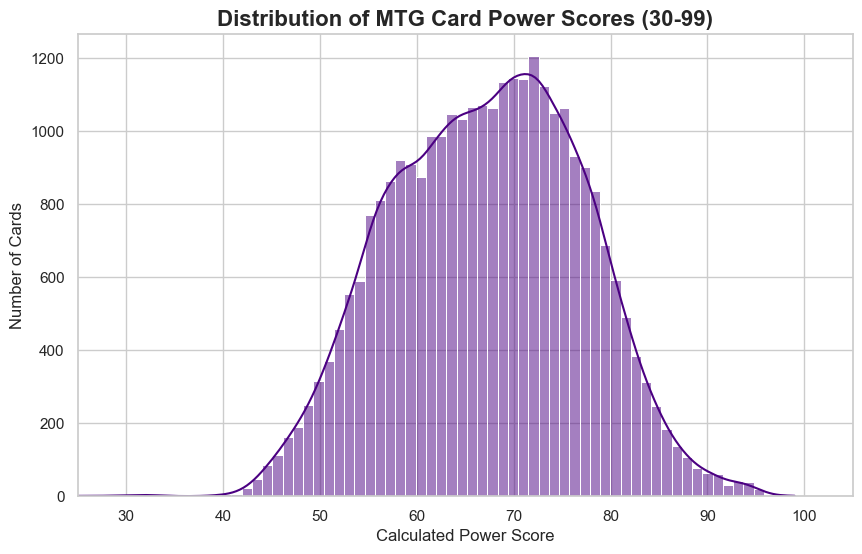

In [7]:
# --- TRUE LOGARITHMIC SCALING ---
MIN_SCORE = 25
MAX_SCORE = 99

log_min = df['log_inclusion_rate'].min()
log_max = df['log_inclusion_rate'].max()

# Apply the Min-Max formula to map it strictly between 25.0 and 99.0
df['log10_power_score'] = MIN_SCORE + ((df['log_inclusion_rate'] - log_min) * (MAX_SCORE - MIN_SCORE)) / (log_max - log_min)

print(f"Scores calculated! Range: {df['log10_power_score'].min():.4f} to {df['log10_power_score'].max():.4f}")

sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))
sns.histplot(df['log10_power_score'], bins=70, kde=True, color='indigo')

plt.title('Distribution of MTG Card Power Scores (30-99)', fontsize=16, fontweight='bold')
plt.xlabel('Calculated Power Score', fontsize=12)
plt.ylabel('Number of Cards', fontsize=12)
plt.xlim(25, 105)
plt.show()

## Create text embeddings

In [8]:
print("Loading all-MiniLM-L6-v2...")
model = SentenceTransformer('all-MiniLM-L6-v2')

print("Generating 384-dimensional embeddings...")
embeddings = model.encode(
    df['transformer_input'].tolist(), 
    batch_size=256, 
    show_progress_bar=True,
    convert_to_numpy=True 
)

print(f"Text Embeddings generated! Shape: {embeddings.shape}")

Loading all-MiniLM-L6-v2...
Generating 384-dimensional embeddings...


Batches: 100%|██████████| 116/116 [03:30<00:00,  1.82s/it]

Text Embeddings generated! Shape: (29616, 384)


## Create numerical and boolean features

In [ ]:
# Clean and Extract Numerical Features
def safe_to_float(val):
    if pd.isna(val):
        return np.nan
    val = str(val).replace('*', '0').replace('+', '') # Treat * as 0
    try:
        return float(val)
    except ValueError:
        return np.nan
    
def count_colors(val):
    if isinstance(val, list):
        return len(val)
    if isinstance(val, str):
        # Handle string representations like "['W', 'U']" or "[]" safely
        try:
            parsed = ast.literal_eval(val)
            if isinstance(parsed, list):
                return len(parsed)
        except (ValueError, SyntaxError):
            pass
    return 0

def check_is_modal(row):
    # 1. Check for literal bullet points in Oracle text (Charms, Commands, etc.)
    if '•' in str(row.get('oracle_text', '')):
        return 1
    
    # 2. Check for Split spells (e.g., Fire // Ice)
    faces = row.get('card_faces')
    if isinstance(faces, list) and len(faces) > 1:
        # Check if EVERY face is an Instant or Sorcery
        all_spells = all(
            ('Instant' in str(face.get('type_line', '')) or 'Sorcery' in str(face.get('type_line', ''))) 
            for face in faces
        )
        if all_spells:
            return 1
            
    return 0

def check_is_transform(row):
    faces = row.get('card_faces')
    if isinstance(faces, list) and len(faces) > 1:
        # Check if EVERY face is a permanent (i.e., NOT an Instant and NOT a Sorcery)
        all_permanents = all(
            ('Instant' not in str(face.get('type_line', '')) and 'Sorcery' not in str(face.get('type_line', ''))) 
            for face in faces
        )
        if all_permanents:
            return 1
            
    return 0

print("Processing tabular features...")
# --- NUMERICAL FEATURES ---
df['num_cmc'] = pd.to_numeric(df['cmc'], errors='coerce').fillna(0)
df['num_power'] = df['power'].apply(safe_to_float)
df['num_toughness'] = df['toughness'].apply(safe_to_float)
df['num_loyalty'] = df['loyalty'].apply(safe_to_float)
df['num_colors'] = df['color_identity'].apply(count_colors)

# --- BOOLEAN FEATURES ---
df['bool_is_game_changer'] = df['game_changer'].fillna(False).astype(int)
df['bool_power_var'] = df['power'].astype(str).str.contains(r'[\*X]', na=False).astype(int)
df['bool_toughness_var'] = df['toughness'].astype(str).str.contains(r'[\*X]', na=False).astype(int)
df['bool_is_planeswalker'] = df['type_line'].astype(str).str.contains('Planeswalker', case=False, na=False).astype(int)
df['bool_has_x_cost'] = df['mana_cost'].astype(str).str.contains('{X}', case=False, na=False).astype(int)
df['bool_is_legendary'] = df['type_line'].astype(str).str.contains('Legendary', case=False, na=False).astype(int)
df['bool_is_colorless'] = df['color_identity'].apply(lambda x: 1 if (isinstance(x, list) and len(x) == 0) or str(x) == '[]' else 0)
df['bool_is_modal'] = df.apply(check_is_modal, axis=1)
df['bool_is_transform'] = df.apply(check_is_transform, axis=1)
df['bool_is_saga'] = df['type_line'].astype(str).str.contains(r'\bSaga\b', case=False, na=False).astype(int)
df['bool_is_class'] = df['type_line'].astype(str).str.contains(r'\bClass\b', case=False, na=False).astype(int)
# TODO: add is_vanilla and is_keyword_only

# --- Compose model data ---
boolean_cols = [col for col in df.columns if col.startswith('bool_')]
boolean_features = df[boolean_cols].values

numerical_cols = [col for col in df.columns if col.startswith('num_')]
numerical_features = df[numerical_cols].fillna(-999).values

X = np.hstack((embeddings, numerical_features, boolean_features))
y = df['log10_power_score'].values

print(f"Final Feature Matrix (X) ready! Shape: {X.shape}")
print(f"Target Variable (y) ready! Shape: {y.shape}")
print(f"Features mapped: {len(numerical_cols)} numerical, {len(boolean_cols)} boolean")

df.head()

Processing tabular features...
Final Feature Matrix (X) ready! Shape: (29616, 400)
Target Variable (y) ready! Shape: (29616,)
Features mapped: 5 numerical, 11 boolean


In [30]:
print("Attaching embeddings to the DataFrame...")
embed_cols = [f"embed_{i}" for i in range(embeddings.shape[1])]
embeddings_df = pd.DataFrame(embeddings, columns=embed_cols, index=df.index)
df_final = pd.concat([df, embeddings_df], axis=1)

print(f"Embeddings attached! New DataFrame shape: {df_final.shape}")
print(f"Exporting to {OUTPUT_DATA_PATH}...")

df_final.to_parquet(OUTPUT_DATA_PATH, index=False)
print("Export complete! Your dataset is ready for training.")

Attaching embeddings to the DataFrame...
Embeddings attached! New DataFrame shape: (29616, 421)
Exporting to card_strength_dataset.csv...
Export complete! Your dataset is ready for training.
